In [1]:
import numpy as np
import os 
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import savgol_filter
from sklearn.preprocessing import MinMaxScaler
import warnings
from scipy import stats
import seaborn as sns
import scipy.ndimage
import scipy.stats as stats
from scipy.ndimage import gaussian_filter1d
from scipy.stats import ranksums
from numba import jit
import matplotlib as mpl
import random
import pickle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from typing import List, Tuple, Dict, Literal
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False

import gzip
import sys

# # Add the folder containing your modules to the path
# folder_path = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code'  # Replace with actual path
# sys.path.insert(0, folder_path)

# from avc_analysis import *
# analysis = avc_analysis()
# plotter = avc_plotting()

# from data_loading import *

# loader = DataLoader()  

#figures_dir = 

from matplotlib import rcParams

# Set publication style
rcParams['font.family'] = 'Arial'

## Define simulated neurons types 

In [2]:
# Section 1: Define Simulated Neuron Types

class SimulatedNeuron:
    """
    Define a simulated neuron with ground-truth parameters.
    
    Parameters
    ----------
    name : str
        Descriptive name for this neuron type
    weight_params : dict
        Dictionary mapping predictor group names to weight specifications
        Format: {'group_name': {'indices': [...], 'weights': [...]}}
        - 'indices': which features within the group to modulate (relative to group start)
        - 'weights': weight values for those features
    baseline_log_rate : float
        Baseline log firing rate (w0), default = -2.0 (corresponds to ~0.135 Hz baseline)
    noise_scale : float
        Additional noise multiplier (1.0 = pure Poisson, >1.0 = overdispersed)
    context_modulation : dict or None
        If not None, modulates weights by context
        Format: {context_id: weight_multiplier}
        e.g., {0: 1.0, 1: 1.5, 2: 0.5} means 1.5× weights in context 1, 0.5× in context 2
    per_context_weight_params : dict or None
        If not None, specifies DIFFERENT weight_params per context.
        Format: {context_id: weight_params_dict}
        Used for context-switch neurons (e.g., L-preference in ctx1, R-preference in ctx2).
        Contexts not listed get baseline-only activity (no task weights).
        Takes precedence over weight_params when specified.
    """
    def __init__(self, name, weight_params, baseline_log_rate=-0.0,
                 noise_scale=1.0, context_modulation=None,
                 per_context_weight_params=None):
        self.name = name
        self.weight_params = weight_params
        self.baseline_log_rate = baseline_log_rate
        self.noise_scale = noise_scale
        self.context_modulation = context_modulation
        self.per_context_weight_params = per_context_weight_params
    
    def build_weight_vector(self, predictor_info, total_features):
        """
        Build the true weight vector for this neuron.
        
        Returns
        -------
        w_true : ndarray, shape (total_features,)
            Full weight vector with zeros for non-modulated features
        """
        w_true = np.zeros(total_features)
        
        for group_name, params in self.weight_params.items():
            if group_name not in predictor_info:
                print(f"Warning: Group '{group_name}' not in predictor_info, skipping")
                continue
            
            group_start = predictor_info[group_name]['start']
            group_end = predictor_info[group_name]['end']
            
            # Get relative indices and weights
            rel_indices = np.array(params['indices'])
            weights = np.array(params['weights'])
            
            # Convert to absolute indices
            abs_indices = group_start + rel_indices
            
            # Check bounds
            if np.any(abs_indices >= group_end):
                print(f"Warning: Some indices for '{group_name}' exceed group bounds")
                abs_indices = abs_indices[abs_indices < group_end]
                weights = weights[:len(abs_indices)]
            
            # Assign weights
            w_true[abs_indices] = weights
        
        return w_true
    
    def __repr__(self):
        return f"SimulatedNeuron('{self.name}', groups={list(self.weight_params.keys())})"

def create_neuron_library():
    """
    Create a library of simulated neuron types for testing.
    """
    neurons = []

    # ========================================================================
    # 1. PURE POSITION NEURONS
    # ========================================================================
    baseline_log_rate = -0.1
    noise_scale = 0
    neurons.append(SimulatedNeuron(
        name='position_early_stem',
        weight_params={
            'position_only': {
                'indices': [0, 1, 2],
                'weights': [0.8, 1.2, 0.8]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    neurons.append(SimulatedNeuron(
        name='position_late_stem',
        weight_params={
            'position_only': {
                'indices': [7, 8, 9],
                'weights': [0.6, 1.0, 0.6]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 2. PURE SENSORY NEURONS (CONTEXT-INVARIANT)
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='auditory_left_invariant',
        weight_params={
            'sound': {
                'indices': list(range(0, 10)),
                'weights': [0.5, 0.7, 0.9, 1.1, 1.0, 0.9, 0.7, 0.5, 0.3, 0.2]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale,
        context_modulation=None
    ))

    neurons.append(SimulatedNeuron(
        name='auditory_right_invariant',
        weight_params={
            'sound': {
                'indices': list(range(10, 20)),
                'weights': [0.4, 0.6, 0.8, 1.0, 1.1, 0.9, 0.6, 0.4, 0.2, 0.1]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    neurons.append(SimulatedNeuron(
        name='visual_0deg_invariant',
        weight_params={
            'visual': {
                'indices': list(range(0, 10)),
                'weights': [0.3, 0.5, 0.8, 1.0, 0.9, 0.7, 0.5, 0.3, 0.2, 0.1]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    neurons.append(SimulatedNeuron(
        name='visual_90deg_invariant',
        weight_params={
            'visual': {
                'indices': list(range(10, 20)),
                'weights': [0.4, 0.7, 0.9, 1.1, 1.0, 0.8, 0.5, 0.3, 0.2, 0.1]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 3. CHOICE NEURONS - CONTEXT-INVARIANT
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='choice_left_invariant',
        weight_params={
            'choice_spatial': {
                'indices': list(range(0, 30)),
                'weights': np.concatenate([
                    np.linspace(0.3, 1.0, 15),
                    np.linspace(1.0, 0.5, 15)
                ]).tolist()
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale,
        context_modulation=None
    ))

    neurons.append(SimulatedNeuron(
        name='choice_right_invariant',
        weight_params={
            'choice_spatial': {
                'indices': list(range(30, 60)),
                'weights': np.concatenate([
                    np.linspace(0.3, 1.0, 15),
                    np.linspace(1.0, 0.5, 15)
                ]).tolist()
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 4. CHOICE NEURONS - CONTEXT-DEPENDENT
    #
    # Three flavours:
    #   choice_left_ctx1_only   – L-choice tuned, fires ONLY in context 1
    #                             (near-zero gain in ctx 0 and 2)
    #   choice_right_ctx2_only  – R-choice tuned, fires ONLY in context 2
    #   choice_switch_ctx1L_ctx2R – L-preference in ctx1, R-preference in ctx2
    #                             (uses per_context_weight_params; baseline-only in ctx0)
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='choice_left_ctx1_only',
        weight_params={
            'choice_spatial': {
                'indices': list(range(0, 30)),
                'weights': np.concatenate([
                    np.linspace(0.3, 0.9, 15),
                    np.linspace(0.9, 0.5, 15)
                ]).tolist()
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale,
        context_modulation={0: 0.05, 1: 1.0, 2: 0.05}   # active ONLY in ctx 1
    ))

    neurons.append(SimulatedNeuron(
        name='choice_right_ctx2_only',
        weight_params={
            'choice_spatial': {
                'indices': list(range(30, 60)),
                'weights': np.concatenate([
                    np.linspace(0.3, 0.9, 15),
                    np.linspace(0.9, 0.5, 15)
                ]).tolist()
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale,
        context_modulation={0: 0.05, 1: 0.05, 2: 1.0}   # active ONLY in ctx 2
    ))

    neurons.append(SimulatedNeuron(
        name='choice_switch_ctx1L_ctx2R',
        weight_params={},           # no global task weights
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale,
        # per_context_weight_params overrides weight_params per context
        per_context_weight_params={
            1: {                    # ctx 1 → Left-choice preference
                'choice_spatial': {
                    'indices': list(range(0, 30)),
                    'weights': np.concatenate([
                        np.linspace(0.3, 0.9, 15),
                        np.linspace(0.9, 0.5, 15)
                    ]).tolist()
                }
            },
            2: {                    # ctx 2 → Right-choice preference
                'choice_spatial': {
                    'indices': list(range(30, 60)),
                    'weights': np.concatenate([
                        np.linspace(0.3, 0.9, 15),
                        np.linspace(0.9, 0.5, 15)
                    ]).tolist()
                }
            },
            # ctx 0 not listed → baseline-only activity
        }
    ))

    # ========================================================================
    # 5. TURN ONSET NEURONS
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='turn_left_onset',
        weight_params={
            'turn_onset': {
                'indices': [0, 1, 2, 3],
                'weights': [0.8, 1.2, 0.9, 0.5]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    neurons.append(SimulatedNeuron(
        name='turn_right_onset',
        weight_params={
            'turn_onset': {
                'indices': [4, 5, 6, 7],
                'weights': [0.7, 1.1, 1.0, 0.6]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 6. REWARD/OUTCOME NEURONS
    #
    # reward_hit_neuron   – fires after CORRECT outcomes only (reward delivery)
    # reward_miss_neuron  – fires after ERROR outcomes only (omission signal)
    # reward_value_neuron – mixed: responds to both (positive for hit, weaker for miss)
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='reward_hit_neuron',
        weight_params={
            'reward_hit': {
                'indices': [0, 1, 2, 3],
                'weights': [0.3, 0.8, 1.2, 0.7]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    neurons.append(SimulatedNeuron(
        name='reward_miss_neuron',
        weight_params={
            'reward_miss': {
                'indices': [0, 1, 2, 3],
                'weights': [0.4, 0.9, 1.0, 0.5]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    neurons.append(SimulatedNeuron(
        name='reward_value_neuron',
        weight_params={
            'reward_hit':  {'indices': [0, 1, 2, 3], 'weights': [0.5, 1.0, 1.2, 0.6]},
            'reward_miss': {'indices': [0, 1, 2, 3], 'weights': [0.2, 0.4, 0.3, 0.1]},
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 7. VELOCITY NEURONS
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='velocity_forward',
        weight_params={
            'velocity': {
                'indices': list(range(0, 5)),
                'weights': [0.5, 0.7, 0.9, 0.7, 0.5]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 8. MIXED SELECTIVITY NEURONS
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='choice_left_plus_reward_hit',
        weight_params={
            'choice_spatial': {
                'indices': list(range(10, 25)),
                'weights': np.linspace(0.4, 0.8, 15).tolist()
            },
            'reward_hit': {
                'indices': [1, 2, 3],
                'weights': [0.5, 0.7, 0.4]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    neurons.append(SimulatedNeuron(
        name='auditory_left_plus_choice_left',
        weight_params={
            'sound': {
                'indices': list(range(2, 8)),
                'weights': [0.6, 0.8, 1.0, 0.8, 0.6, 0.4]
            },
            'choice_spatial': {
                'indices': list(range(5, 20)),
                'weights': np.linspace(0.3, 0.7, 15).tolist()
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 9. WEAK MODULATION NEURONS (sensitivity testing)
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='choice_right_weak',
        weight_params={
            'choice_spatial': {
                'indices': list(range(30, 50)),
                'weights': np.linspace(0.1, 0.3, 20).tolist()
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale
    ))

    # ========================================================================
    # 10. PURE CONTEXT NEURONS
    #
    # These neurons have NO task predictor weights — their selectivity comes
    # entirely from context_modulation on the baseline log-rate.
    #
    # context_modulation multiplies the *effective firing rate* per context:
    #   log_rate(ctx) = baseline_log_rate + log(multiplier)
    #
    # Design:
    #   context_audio_selective  → fires ~3× more in Context 1 (audio-guided)
    #                              than in Contexts 0 and 2
    #   context_visual_selective → fires ~3× more in Context 2 (visual-guided)
    #                              than in Contexts 0 and 1
    #
    # The weight_params dict is intentionally empty — the GLM has no predictor
    # that encodes context directly, so a well-fitted model should assign near-
    # zero weights to all groups and show a large unexplained residual that
    # tracks context. This makes these neurons a useful test of what the GLM
    # *cannot* capture.
    # ========================================================================

    neurons.append(SimulatedNeuron(
        name='context_audio_selective',
        weight_params={
            # Small position-only weights so the neuron isn't completely
            # invisible to the GLM — it will fire during the trial, just
            # with a strong context-dependent gain.
            'position_only': {
                'indices': [3, 4, 5],       # Mid-stem position bumps
                'weights': [0.3, 0.4, 0.3]  # Weak, uniform across stem
            }
        },
        baseline_log_rate=baseline_log_rate,             # Slightly higher baseline so it's detectable
        noise_scale=noise_scale,
        context_modulation={
            0: 0.4,   # Context 0 (congruent): suppressed  (~0.4× rate)
            1: 3.0,   # Context 1 (audio):     strongly active (~3× rate)
            2: 0.4,   # Context 2 (visual):    suppressed  (~0.4× rate)
        }
    ))

    neurons.append(SimulatedNeuron(
        name='context_visual_selective',
        weight_params={
            'position_only': {
                'indices': [3, 4, 5],
                'weights': [0.3, 0.4, 0.3]
            }
        },
        baseline_log_rate=baseline_log_rate,
        noise_scale=noise_scale,
        context_modulation={
            0: 0.4,   # Context 0 (congruent): suppressed
            1: 0.4,   # Context 1 (audio):     suppressed
            2: 3.0,   # Context 2 (visual):    strongly active (~3× rate)
        }
    ))

    return neurons

In [3]:
# Create the neuron library
print("Creating Simulated Neuron Library")
print("=" * 70)

neuron_library = create_neuron_library()

# Display summary
for i, neuron in enumerate(neuron_library):
    print(f"\n{i+1}. {neuron.name}")
    print(f"   Groups: {list(neuron.weight_params.keys())}")
    print(f"   Baseline: {neuron.baseline_log_rate:.2f} (rate ≈ {np.exp(neuron.baseline_log_rate):.3f})")
    if neuron.context_modulation is not None:
        print(f"   Context modulation: {neuron.context_modulation}")
    total_weights = sum(len(params['weights']) for params in neuron.weight_params.values())
    print(f"   Non-zero weights: {total_weights}")

print(f"\n{'=' * 70}")
print(f"Total simulated neurons: {len(neuron_library)}")
print("✓ Neuron library created")

Creating Simulated Neuron Library

1. position_early_stem
   Groups: ['position_only']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 3

2. position_late_stem
   Groups: ['position_only']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 3

3. auditory_left_invariant
   Groups: ['sound']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 10

4. auditory_right_invariant
   Groups: ['sound']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 10

5. visual_0deg_invariant
   Groups: ['visual']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 10

6. visual_90deg_invariant
   Groups: ['visual']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 10

7. choice_left_invariant
   Groups: ['choice_spatial']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 30

8. choice_right_invariant
   Groups: ['choice_spatial']
   Baseline: 1.60 (rate ≈ 4.953)
   Non-zero weights: 30

9. choice_left_ctx1_only
   Groups: ['choice_spatial']
   Baseline: 1.60 (rate ≈ 4.953)
   Contex

## Create trial structure 

In [4]:
# Section 2: Generate Synthetic Trial Structure

def generate_synthetic_trials(n_trials_per_context=100, sampling_rate=15.6, seed=42):
    """
    Generate synthetic trial structure with realistic movement and event timing.
    
    Parameters
    ----------
    n_trials_per_context : int
        Number of trials to generate per context (0, 1, 2)
    sampling_rate : float
        Imaging frame rate (Hz)
    seed : int
        Random seed for reproducibility
    
    Returns
    -------
    synthetic_glm_dict : dict
        Dictionary with trial_idx as keys, matching glm_data_dict format
    """
    rng = np.random.default_rng(seed)
    synthetic_glm_dict = {}
    
    # Trial timing parameters (in seconds)
    stem_duration_range = (3.0, 5.0)  # Time to traverse stem
    arm_duration_range = (1.5, 3.0)   # Time in choice arm
    iti_duration_range = (2.0, 3.0)   # Inter-trial interval
    
    # Position parameters
    stem_length = 500.0  # Y position units
    arm_length = 200.0   # X position units (after turn)
    
    # Stimulus parameters
    audio_stimuli = [-90.0, 90.0]  # Left, Right
    visual_stimuli = [0.0, 90.0]   # 0°, 90°

    # Context-dependent error rates
    # Context 0 (congruent): easy → few errors
    # Context 1 (visual-only): harder → more errors
    # Context 2 (audio-only): harder → more errors
    error_rates = {0: 0.05, 1: 0.20, 2: 0.20}

    trial_counter = 0

    for context in [0, 1, 2]:
        # Stimulus availability per context:
        #   Context 0 (congruent) : audio + visual both present
        #   Context 1 (visual-guided): visual only  (Audio_Stim = nan)
        #   Context 2 (audio-guided) : audio only   (Visual_Stim = nan)
        has_audio  = context in [0, 2]
        has_visual = context in [0, 1]

        ctx_audio   = audio_stimuli  if has_audio  else [np.nan]
        ctx_visual  = visual_stimuli if has_visual else [np.nan]

        n_conditions = 2 * len(ctx_audio) * len(ctx_visual)   # choices × stimuli
        n_per_condition = n_trials_per_context // n_conditions
        extra_trials    = n_trials_per_context % n_conditions

        condition_list = []
        for choice in [0, 1]:
            for audio_stim in ctx_audio:
                for visual_stim in ctx_visual:
                    condition_list.extend(
                        [(context, choice, audio_stim, visual_stim)] * n_per_condition
                    )

        if extra_trials > 0:
            extra = rng.choice(len(condition_list), size=extra_trials, replace=False)
            for idx in extra:
                condition_list.append(condition_list[idx])

        rng.shuffle(condition_list)

        # Generate trials
        for ctx, choice, audio_stim, visual_stim in condition_list:
            
            # -------------------------------
            # Trial timing
            # -------------------------------
            stem_duration = rng.uniform(*stem_duration_range)
            arm_duration = rng.uniform(*arm_duration_range)
            iti_duration = rng.uniform(*iti_duration_range)
            
            stem_frames = int(stem_duration * sampling_rate)
            arm_frames = int(arm_duration * sampling_rate)
            iti_frames = int(iti_duration * sampling_rate)
            trial_frames = stem_frames + arm_frames + iti_frames
            
            # Event frames
            sound_onset_frame = int(rng.uniform(0.3, 0.8) * sampling_rate)  # 0.3-0.8s into trial
            visual_onset_frame = sound_onset_frame + int(rng.uniform(0.0, 0.5) * sampling_rate)
            choice_frame = stem_frames - 1  # End of stem
            reward_frame = stem_frames + int(0.5 * sampling_rate)  # 0.5s after turn
            iti_start_frame = stem_frames + arm_frames
            
            # -------------------------------
            # Movement trajectory
            # -------------------------------
            # Y position: linear progression along stem, then plateau
            y_position = np.zeros(trial_frames)
            y_position[:stem_frames] = np.linspace(0, stem_length, stem_frames)
            y_position[stem_frames:] = stem_length  # Stay at end
            
            # X position: centered until turn, then shift left or right
            x_position = np.zeros(trial_frames)
            if choice == 0:  # Left turn
                x_position[stem_frames:] = np.linspace(0, -arm_length, arm_frames + iti_frames)
            else:  # Right turn
                x_position[stem_frames:] = np.linspace(0, arm_length, arm_frames + iti_frames)
            
            # Velocities: derivative of position (with smoothing)
            y_velocity = np.gradient(y_position) * sampling_rate
            x_velocity = np.gradient(x_position) * sampling_rate
            
            # Add some noise to velocities for realism
            y_velocity += rng.normal(0, 5, trial_frames)
            x_velocity += rng.normal(0, 5, trial_frames)
            
            # Smooth velocities
            from scipy.ndimage import gaussian_filter1d
            y_velocity = gaussian_filter1d(y_velocity, sigma=2)
            x_velocity = gaussian_filter1d(x_velocity, sigma=2)
            
            # -------------------------------
            # Outcome (probabilistic, context-dependent error rate)
            # -------------------------------
            outcome = 0 if rng.random() < error_rates[context] else 1  # 1=correct, 0=error

            # On error trials reward_frame shifts to iti_start (no reward delivered)
            if outcome == 0:
                reward_frame = iti_start_frame

            # -------------------------------
            # Trial type ID (for bookkeeping)
            # -------------------------------
            _a = int(audio_stim > 0)  if not np.isnan(audio_stim)  else 0
            _v = int(visual_stim > 0) if not np.isnan(visual_stim) else 0
            trial_type = int(f"{context}{choice}{_a}{_v}")
            
            # -------------------------------
            # Visual stimulus end frame
            # -------------------------------
            # Visual stimulus stays on until choice
            visual_end_frame = choice_frame
            stim_end_frame = choice_frame  # Audio also ends at choice
            
            # -------------------------------
            # Build trial dictionary (matching glm_data_dict format)
            # -------------------------------
            synthetic_glm_dict[trial_counter] = {
                'trial_id': trial_counter,
                'context': context,
                'choice': choice,
                'outcome': outcome,
                'trial_type': trial_type,
                'Visual_Stim': visual_stim,
                'Audio_Stim': audio_stim,
                
                # Movement data
                'movement': {
                    'y_position': y_position,
                    'x_position': x_position,
                    'y_velocity': y_velocity,
                    'x_velocity': x_velocity,
                },
                
                # Event timings
                'events': {
                    'sound_onset': sound_onset_frame,
                    'visual_onset': visual_onset_frame,
                    'stim_end': stim_end_frame,
                    'visual_end': visual_end_frame,
                    'choice_frame': choice_frame,
                    'reward_frame': reward_frame,
                    'iti_start': iti_start_frame,
                    'trial_length': trial_frames,
                },
                
                # Placeholder for neural data (will be filled in Section 4)
                'neural': None
            }
            
            trial_counter += 1
    
    return synthetic_glm_dict


# Generate synthetic trials
print("\nGenerating Synthetic Trial Structure...")
print("=" * 70)

synthetic_glm_dict = generate_synthetic_trials(
    n_trials_per_context=100,
    sampling_rate=15.6,
    seed=42
)

n_trials = len(synthetic_glm_dict)
print(f"\n✓ Generated {n_trials} synthetic trials")

# -------------------------------
# Verify balance
# -------------------------------
print("\nTrial Balance:")
print("-" * 70)

# Context balance
for ctx in [0, 1, 2]:
    n_ctx = sum(1 for t in synthetic_glm_dict.values() if t['context'] == ctx)
    print(f"Context {ctx}: {n_ctx} trials")

# Choice balance per context
print("\nChoice balance per context:")
for ctx in [0, 1, 2]:
    trials_ctx = [t for t in synthetic_glm_dict.values() if t['context'] == ctx]
    n_left = sum(1 for t in trials_ctx if t['choice'] == 0)
    n_right = sum(1 for t in trials_ctx if t['choice'] == 1)
    print(f"  Context {ctx}: Left={n_left}, Right={n_right}")

# Stimulus balance per context
print("\nAudio stimulus balance per context:")
for ctx in [0, 1, 2]:
    trials_ctx = [t for t in synthetic_glm_dict.values() if t['context'] == ctx]
    n_left_audio = sum(1 for t in trials_ctx if t['Audio_Stim'] == -90.0)
    n_right_audio = sum(1 for t in trials_ctx if t['Audio_Stim'] == 90.0)
    print(f"  Context {ctx}: Left audio={n_left_audio}, Right audio={n_right_audio}")

print("\nVisual stimulus balance per context:")
for ctx in [0, 1, 2]:
    trials_ctx = [t for t in synthetic_glm_dict.values() if t['context'] == ctx]
    n_0deg = sum(1 for t in trials_ctx if t['Visual_Stim'] == 0.0)
    n_90deg = sum(1 for t in trials_ctx if t['Visual_Stim'] == 90.0)
    print(f"  Context {ctx}: 0° visual={n_0deg}, 90° visual={n_90deg}")

# Frame statistics
total_frames = sum(t['events']['trial_length'] for t in synthetic_glm_dict.values())
avg_frames = total_frames / n_trials
print(f"\nFrame Statistics:")
print(f"  Total frames: {total_frames:,}")
print(f"  Average frames/trial: {avg_frames:.1f}")
print(f"  Duration: {total_frames/15.6:.1f} seconds ({total_frames/15.6/60:.1f} minutes)")

print("\n" + "=" * 70)
print("✓ Synthetic trial structure created and verified")


Generating Synthetic Trial Structure...

✓ Generated 300 synthetic trials

Trial Balance:
----------------------------------------------------------------------
Context 0: 100 trials
Context 1: 100 trials
Context 2: 100 trials

Choice balance per context:
  Context 0: Left=50, Right=50
  Context 1: Left=50, Right=50
  Context 2: Left=50, Right=50

Audio stimulus balance per context:
  Context 0: Left audio=50, Right audio=50
  Context 1: Left audio=0, Right audio=0
  Context 2: Left audio=50, Right audio=50

Visual stimulus balance per context:
  Context 0: 0° visual=50, 90° visual=50
  Context 1: 0° visual=50, 90° visual=50
  Context 2: 0° visual=0, 90° visual=0

Frame Statistics:
  Total frames: 40,224
  Average frames/trial: 134.1
  Duration: 2578.5 seconds (43.0 minutes)

✓ Synthetic trial structure created and verified


## Predictor Builder

In [5]:
def create_cosine_bumps(x, centers, widths):
    """
    Create raised cosine bumps (matching Harvey Lab tutorial).
    
    Parameters
    ----------
    x : ndarray, shape (n_samples,)
        Positions/times to evaluate bumps at
    centers : ndarray, shape (n_bumps,)
        Center positions of each bump
    widths : ndarray, shape (n_bumps,)
        Width of each bump
        
    Returns
    -------
    bases : ndarray, shape (n_samples, n_bumps)
        Evaluated basis functions
    """
    assert centers.shape == widths.shape, "Centers and widths must have same shape"
    x_reshape = np.asarray(x).reshape(-1)
    bases = np.zeros((x_reshape.shape[0], centers.shape[0]))
    
    for idx, cent in enumerate(centers):
        w = widths[idx]
        bases[:, idx] = (np.cos(2 * np.pi * (x_reshape - cent) / w) * 0.5 + 0.5) * \
                        (np.abs(x_reshape - cent) < w / 2)
    
    return bases
    
class GLMPredictorBuilder:
    """
    GLM predictor builder.
    
    Position-dependent (0-500):
    - Position-only: 10 bumps
    - Visual × Pos: 20 (2 orientations × 10)
    - Audio × Pos: 20 (2 locations × 10, starts at y=50)
    - Choice place fields: 60 (2 directions × 30, truncated at turn)
    - Velocity × Pos: 20 (4 directions × 5)
    
    Temporally-dependent:
    - Turn onset: 8 (2 directions × 4 forward only, choice-specific)
    - Reward-hit: 4 forward bumps (correct trials only)
    - Reward-miss: 4 forward bumps (error trials only)

    Total: 146 predictors (145 + constant)
    """
    
    def __init__(
        self,
        sampling_rate=15.6,
        # Position parameters
        n_pos_bases=10,
        stem_y_max=500.0,
        pos_bump_width_ratio=4.0,
        audio_start_position=50.0,
        # Velocity
        n_vel_bases=5,
        # Spatial choice
        n_place_fields=30,
        # Temporal parameters
        n_turn_bases=4,  # Per direction, forward only
        turn_window=1.0,
        n_reward_bases=8,
        reward_window=2.0,
        temporal_bump_width_ratio=4.0,
        # Event derivation
        outcome_offset_from_iti=0,
        turn_y_thresh=505.0,
        turn_x_vel_thresh=20.0,
        visual_y_thresh=500.0,
        # Modular inclusion flags
        include_position_only=True,
        include_sound_position=True,
        include_visual_position=True,
        include_velocity=True,
        include_spatial_choice=True,
        include_turn_onset=True,
        include_reward_hit=True,
        include_reward_miss=True,
    ):
        self.sampling_rate = sampling_rate
        
        # Position
        self.n_pos_bases = n_pos_bases
        self.stem_y_max = stem_y_max
        self.pos_bump_width_ratio = pos_bump_width_ratio
        self.audio_start_position = audio_start_position
        
        # Velocity
        self.n_vel_bases = n_vel_bases
        
        # Spatial choice
        self.n_place_fields = n_place_fields
        
        # Temporal
        self.n_turn_bases = n_turn_bases
        self.turn_window = turn_window
        self.n_reward_bases = n_reward_bases
        self.reward_window = reward_window
        self.temporal_bump_width_ratio = temporal_bump_width_ratio
        
        # Event derivation
        self.outcome_offset_from_iti = outcome_offset_from_iti
        self.turn_y_thresh = turn_y_thresh
        self.turn_x_vel_thresh = turn_x_vel_thresh
        self.visual_y_thresh = visual_y_thresh
        
        # Inclusion flags
        self.include_position_only = include_position_only
        self.include_sound_position = include_sound_position
        self.include_visual_position = include_visual_position
        self.include_velocity = include_velocity
        self.include_spatial_choice = include_spatial_choice
        self.include_turn_onset = include_turn_onset
        self.include_reward_hit  = include_reward_hit
        self.include_reward_miss = include_reward_miss
    
    def _derive_events(self, trial, movement):
        """Derive missing event timings from trial and movement data."""
        events = trial.get("events", {}).copy()
        
        # Choice frame
        if "choice_frame" not in events:
            iti_start = events.get("iti_start")
            if iti_start is not None and iti_start > 0:
                events["choice_frame"] = iti_start - 1
        
        # Reward frame (at ITI start + offset)
        if "reward_frame" not in events:
            iti_start = events.get("iti_start")
            if iti_start is not None:
                events["reward_frame"] = iti_start + self.outcome_offset_from_iti
        
        # Turn onset frame (choice-aware)
        if "turn_onset" not in events:
            y_pos = np.asarray(movement.get("y_position", [])).flatten()
            x_vel = np.asarray(movement.get("x_velocity", [])).flatten()
            choice = trial.get("choice", 0)
            
            turn_frame = None
            for i in range(len(y_pos)):
                if y_pos[i] > self.turn_y_thresh:
                    if i > 0:
                        # Left turn: negative velocity
                        if choice == 0 and x_vel[i] < -self.turn_x_vel_thresh:
                            turn_frame = i
                            break
                        # Right turn: positive velocity
                        elif choice == 1 and x_vel[i] > self.turn_x_vel_thresh:
                            turn_frame = i
                            break
            
            if turn_frame is not None:
                events["turn_onset"] = turn_frame
        
        return events
    
    def _get_y500_frame(self, movement):
        """Get frame where y_position crosses 500."""
        y_pos = np.asarray(movement.get("y_position", [])).flatten()
        for i, y in enumerate(y_pos):
            if y > self.visual_y_thresh:
                return i
        return len(y_pos)
    
    def _get_audio_start_frame(self, movement):
        """Get frame where y_position crosses audio_start_position (50)."""
        y_pos = np.asarray(movement.get("y_position", [])).flatten()
        for i, y in enumerate(y_pos):
            if y >= self.audio_start_position:
                return i
        return 0
    
    def _build_position_bases(self, movement, n_frames):
        """Build position basis functions (raised cosine along stem 0-500)."""
        y_pos = np.asarray(movement["y_position"]).flatten()
        if y_pos.size < n_frames:
            y_pos = np.pad(y_pos, (0, n_frames - y_pos.size), constant_values=np.nan)
        
        x = y_pos[:n_frames].astype(float)
        n_b = self.n_pos_bases
        stem = self.stem_y_max
        
        if n_b == 1:
            centers = np.array([stem / 2])
            widths = np.array([stem])
        else:
            centers = np.linspace(0, stem, n_b)
            spacing = stem / (n_b - 1)
            widths = np.full(n_b, spacing * self.pos_bump_width_ratio)
        
        bases = create_cosine_bumps(x, centers, widths)
        bases = np.nan_to_num(bases, nan=0.0, posinf=0.0, neginf=0.0)
        
        names = [f"pos_bump_{i+1}" for i in range(n_b)]
        return bases, names
    
    def _build_velocity_bases(self, movement, n_frames):
        """Build velocity basis functions (5 bumps along stem 0-500)."""
        y_pos = np.asarray(movement["y_position"]).flatten()
        if y_pos.size < n_frames:
            y_pos = np.pad(y_pos, (0, n_frames - y_pos.size), constant_values=np.nan)
        
        x = y_pos[:n_frames].astype(float)
        n_b = self.n_vel_bases
        stem = self.stem_y_max
        
        if n_b == 1:
            centers = np.array([stem / 2])
            widths = np.array([stem])
        else:
            centers = np.linspace(0, stem, n_b)
            spacing = stem / (n_b - 1)
            widths = np.full(n_b, spacing * self.pos_bump_width_ratio)
        
        bases = create_cosine_bumps(x, centers, widths)
        bases = np.nan_to_num(bases, nan=0.0, posinf=0.0, neginf=0.0)
        
        return bases
    
    def _build_position_only_trial(self, pos_bases):
        """Position-only (trialPhase) predictors."""
        names = [f"trialPhase_pos{i+1}" for i in range(pos_bases.shape[1])]
        return pos_bases.copy(), names
    
    def _build_sound_position_trial(self, n_frames, audio_start_frame, audio_stim, stim_end_frame, pos_bases):
        """Sound × position predictors (starts at y=50, ends at y=500)."""
        n_b = pos_bases.shape[1]
        pred = np.zeros((n_frames, 2 * n_b))
        names = [f"sound_left_pos{i+1}" for i in range(n_b)] + \
                [f"sound_right_pos{i+1}" for i in range(n_b)]
        
        if np.isnan(audio_stim):
            return pred, names
        
        end_f = min(stim_end_frame, n_frames)
        boxcar_left = np.zeros(n_frames)
        boxcar_right = np.zeros(n_frames)
        
        if audio_start_frame < end_f:
            if audio_stim < 0:  # Left (-90)
                boxcar_left[audio_start_frame:end_f] = 1.0
            else:  # Right (90)
                boxcar_right[audio_start_frame:end_f] = 1.0
        
        pred[:, :n_b] = boxcar_left[:, None] * pos_bases
        pred[:, n_b:] = boxcar_right[:, None] * pos_bases
        
        return pred, names
    
    def _build_visual_position_trial(self, n_frames, stim_onset, visual_end_frame, visual_stim, pos_bases):
        """Visual × position predictors (throughout, ends at y=500)."""
        n_b = pos_bases.shape[1]
        pred = np.zeros((n_frames, 2 * n_b))
        names = [f"visual_0deg_pos{i+1}" for i in range(n_b)] + \
                [f"visual_90deg_pos{i+1}" for i in range(n_b)]
        
        if np.isnan(visual_stim):
            return pred, names
        
        loc = 0 if (float(visual_stim) == -90.0 or float(visual_stim) == 0.0) else 1
        
        start_f = stim_onset
        end_f = min(visual_end_frame, n_frames)
        
        if end_f <= start_f:
            return pred, names
        
        boxcar = np.zeros(n_frames)
        boxcar[start_f:end_f] = 1.0
        
        if loc == 0:
            pred[:, :n_b] = boxcar[:, None] * pos_bases
        else:
            pred[:, n_b:] = boxcar[:, None] * pos_bases
        
        return pred, names
    
    def _build_velocity_trial(self, movement, n_frames, vel_bases):
        """
        Velocity × position predictors.
        4 directions (forward, reverse, leftward, rightward) × 5 position bumps = 20.
        """
        n_b = self.n_vel_bases
        
        # Get velocity data
        y_vel = np.asarray(movement.get("y_velocity", [])).flatten()
        x_vel = np.asarray(movement.get("x_velocity", [])).flatten()
        
        # Pad if needed
        if y_vel.size < n_frames:
            y_vel = np.pad(y_vel, (0, n_frames - y_vel.size), constant_values=0.0)
        if x_vel.size < n_frames:
            x_vel = np.pad(x_vel, (0, n_frames - x_vel.size), constant_values=0.0)
        
        y_vel = y_vel[:n_frames]
        x_vel = x_vel[:n_frames]
        
        # Separate into directions
        forward_vel = np.maximum(y_vel, 0)
        reverse_vel = np.maximum(-y_vel, 0)
        rightward_vel = np.maximum(x_vel, 0)
        leftward_vel = np.maximum(-x_vel, 0)
        
        # Multiply by position bases
        pred = np.zeros((n_frames, 4 * n_b))
        pred[:, 0*n_b:1*n_b] = forward_vel[:, None] * vel_bases
        pred[:, 1*n_b:2*n_b] = reverse_vel[:, None] * vel_bases
        pred[:, 2*n_b:3*n_b] = rightward_vel[:, None] * vel_bases
        pred[:, 3*n_b:4*n_b] = leftward_vel[:, None] * vel_bases
        
        names = [f"vel_forward_pos{i+1}" for i in range(n_b)] + \
                [f"vel_reverse_pos{i+1}" for i in range(n_b)] + \
                [f"vel_right_pos{i+1}" for i in range(n_b)] + \
                [f"vel_left_pos{i+1}" for i in range(n_b)]
        
        return pred, names
    
    def _build_spatial_choice_trial(self, movement, n_frames, choice, turn_frame):
        """
        Spatial choice place fields (0-500, TRUNCATED at turn_onset).
        Only active BEFORE the turn is executed.
        """
        n_pf = self.n_place_fields
        stem = self.stem_y_max
        
        # Define centers and widths for place fields
        if n_pf == 1:
            centers = np.array([stem / 2])
            widths = np.array([stem])
        else:
            centers = np.linspace(0, stem, n_pf)
            spacing = stem / (n_pf - 1)
            widths = np.full(n_pf, spacing * self.pos_bump_width_ratio)
        
        # Get y position
        y_pos = np.asarray(movement["y_position"]).flatten()
        if y_pos.size < n_frames:
            y_pos = np.pad(y_pos, (0, n_frames - y_pos.size), constant_values=np.nan)
        
        x = y_pos[:n_frames].astype(float)
        
        # Evaluate place fields
        place_bases = create_cosine_bumps(x, centers, widths)
        place_bases = np.nan_to_num(place_bases, nan=0.0)
        
        # TRUNCATE at turn onset (zero out after turn)
        if turn_frame < n_frames:
            place_bases[turn_frame:, :] = 0.0
        
        # Only activate the choice-specific channel
        pred = np.zeros((n_frames, 2 * n_pf))
        names = [f"place_left_{i+1}" for i in range(n_pf)] + \
                [f"place_right_{i+1}" for i in range(n_pf)]
        
        if choice == 0:  # Left
            pred[:, :n_pf] = place_bases
        else:  # Right
            pred[:, n_pf:] = place_bases
        
        return pred, names
    
    def _build_turn_onset_trial(self, n_frames, turn_frame, choice):
        """
        Turn onset predictors (4 forward bumps only, choice-specific).
        Left choice trials get left_turn predictors, right choice get right_turn.
        """
        n_b = self.n_turn_bases
        window_frames = int(self.turn_window * self.sampling_rate)
        
        # Forward-only centers
        if n_b == 1:
            centers = np.array([window_frames / 2])
            widths = np.array([window_frames])
        else:
            centers = np.linspace(0, window_frames, n_b)
            spacing = window_frames / (n_b - 1)
            widths = np.full(n_b, spacing * self.temporal_bump_width_ratio)
        
        # Time from turn (forward only)
        time_from_turn = np.arange(n_frames, dtype=float) - turn_frame
        time_from_turn[time_from_turn < 0] = np.nan
        
        # Evaluate temporal bases
        temporal_bases = create_cosine_bumps(time_from_turn, centers, widths)
        temporal_bases = np.nan_to_num(temporal_bases, nan=0.0)
        
        # Only activate choice-specific channel
        pred = np.zeros((n_frames, 2 * n_b))
        names = [f"turn_left_t{i+1}" for i in range(n_b)] + \
                [f"turn_right_t{i+1}" for i in range(n_b)]
        
        if choice == 0:  # Left turn
            pred[:, :n_b] = temporal_bases
        else:  # Right turn
            pred[:, n_b:] = temporal_bases
        
        return pred, names
    
    def _build_reward_outcome_trial(self, n_frames, ref_frame, outcome, target_outcome, group_name):
        """
        Build forward-only temporal bumps anchored to ref_frame.
        Active only when outcome == target_outcome (1=correct hit, 0=error miss).

        Parameters
        ----------
        ref_frame      : int   Anchor frame (reward_frame for hits, iti_start for misses)
        outcome        : int   Trial outcome (1=correct, 0=error)
        target_outcome : int   Which outcome this predictor tracks
        group_name     : str   'reward_hit' or 'reward_miss'
        """
        n_b = self.n_reward_bases // 2   # use 4 forward bumps (half of n_reward_bases)
        window_frames = int(self.reward_window * self.sampling_rate)

        if n_b == 1:
            centers = np.array([window_frames / 2])
            widths  = np.array([window_frames])
        else:
            centers = np.linspace(0, window_frames, n_b)
            spacing = window_frames / (n_b - 1)
            widths  = np.full(n_b, spacing * self.temporal_bump_width_ratio)

        pred = np.zeros((n_frames, n_b))
        names = [f"{group_name}_t{i+1}" for i in range(n_b)]

        # Only fill predictors on trials that match this outcome type
        if outcome == target_outcome:
            time_from_ref = np.arange(n_frames, dtype=float) - ref_frame
            time_from_ref[time_from_ref < 0] = np.nan   # forward only
            bumps = create_cosine_bumps(time_from_ref, centers, widths)
            pred = np.nan_to_num(bumps, nan=0.0)

        return pred, names
    
    def build_design_matrices(self, glm_data_dict):
        """
        Build design matrices for all trials.
        
        Parameters
        ----------
        glm_data_dict : dict or list
            Dictionary/list indexed by trial number
            
        Returns
        -------
        design_matrices : list of ndarray
        predictor_names : list of str
        predictor_info : dict
        """
        if isinstance(glm_data_dict, dict):
            trial_indices = sorted(glm_data_dict.keys())
        else:
            trial_indices = range(len(glm_data_dict))
        
        design_matrices = []
        all_group_parts = []
        
        for idx, trial_idx in enumerate(trial_indices):
            trial_data = glm_data_dict[trial_idx]
            
            movement = trial_data.get("movement", {})
            events_raw = trial_data.get("events", {})
            
            # Get trial length
            if "trial_length" in events_raw:
                n_frames = events_raw["trial_length"]
            else:
                neural_dict = trial_data.get("neural", {})
                if neural_dict:
                    first_metric = next(iter(neural_dict.values()))
                    n_frames = first_metric.shape[0]
                else:
                    raise ValueError(f"Trial {trial_idx} missing trial_length")
            
            # Build trial dict
            trial = {
                "trial_length": n_frames,
                "events": events_raw,
                "audio_stim": trial_data.get("Audio_Stim", np.nan),
                "visual_stim": trial_data.get("Visual_Stim", np.nan),
                "choice": trial_data.get("choice", 0),
                "outcome": trial_data.get("outcome", 0),
            }
            
            # Derive events
            events = self._derive_events(trial, movement)
            
            # Get key frames
            stim_onset = events.get("sound_onset", 0)
            audio_start_frame = self._get_audio_start_frame(movement)
            turn_frame = events.get("turn_onset", n_frames - 1)
            reward_frame = events.get("reward_frame", n_frames - 1)
            iti_start_frame = events.get("iti_start", n_frames - 1)
            outcome = trial.get("outcome", 1)
            y500_frame = self._get_y500_frame(movement)
            
            # Build position bases (10 bumps for main predictors)
            pos_bases, _ = self._build_position_bases(movement, n_frames)
            
            # Build velocity bases (5 bumps)
            vel_bases = self._build_velocity_bases(movement, n_frames) if self.include_velocity else None
            
            trial_parts = []
            
            # 1. Position-only
            if self.include_position_only:
                pred, names = self._build_position_only_trial(pos_bases)
                trial_parts.append(("position_only", pred, names))
            
            # 2. Sound × position (starts at y=50)
            if self.include_sound_position:
                pred, names = self._build_sound_position_trial(
                    n_frames, audio_start_frame, trial["audio_stim"], y500_frame, pos_bases
                )
                trial_parts.append(("sound", pred, names))
            
            # 3. Visual × position
            if self.include_visual_position:
                pred, names = self._build_visual_position_trial(
                    n_frames, stim_onset, y500_frame, trial["visual_stim"], pos_bases
                )
                trial_parts.append(("visual", pred, names))
            
            # 4. Velocity × position
            if self.include_velocity and vel_bases is not None:
                pred, names = self._build_velocity_trial(movement, n_frames, vel_bases)
                trial_parts.append(("velocity", pred, names))
            
            # 5. Spatial choice place fields (TRUNCATED at turn)
            if self.include_spatial_choice:
                pred, names = self._build_spatial_choice_trial(
                    movement, n_frames, trial["choice"], turn_frame
                )
                trial_parts.append(("choice_spatial", pred, names))
            
            # 6. Turn onset (choice-specific, 4 forward only)
            if self.include_turn_onset and turn_frame < n_frames:
                pred, names = self._build_turn_onset_trial(n_frames, turn_frame, trial["choice"])
                trial_parts.append(("turn_onset", pred, names))
            
            # 7a. Reward-hit (4 forward bumps, correct trials only)
            if self.include_reward_hit:
                pred, names = self._build_reward_outcome_trial(
                    n_frames, reward_frame, outcome,
                    target_outcome=1, group_name='reward_hit'
                )
                trial_parts.append(("reward_hit", pred, names))

            # 7b. Reward-miss (4 forward bumps, error trials only, anchored to ITI start)
            if self.include_reward_miss:
                pred, names = self._build_reward_outcome_trial(
                    n_frames, iti_start_frame, outcome,
                    target_outcome=0, group_name='reward_miss'
                )
                trial_parts.append(("reward_miss", pred, names))
            
            # Store metadata from first trial
            if idx == 0:
                all_group_parts = trial_parts
            
            # Concatenate
            trial_preds = [part[1] for part in trial_parts]
            design_trial = np.column_stack(trial_preds) if trial_preds else np.zeros((n_frames, 0))
            
            # Add constant
            constant = np.ones((n_frames, 1))
            design_trial = np.column_stack([design_trial, constant])
            
            design_matrices.append(design_trial)
        
        # Build predictor_names and predictor_info
        predictor_names = []
        predictor_info = {}
        current_idx = 0
        
        for group_name, pred, names in all_group_parts:
            n_pred = pred.shape[1]
            predictor_info[group_name] = {
                "start": current_idx,
                "end": current_idx + n_pred,
                "names": names
            }
            predictor_names.extend(names)
            current_idx += n_pred
        
        # Add constant
        predictor_info["constant"] = {
            "start": current_idx,
            "end": current_idx + 1,
            "names": ["constant"]
        }
        predictor_names.append("constant")
        
        return design_matrices, predictor_names, predictor_info
    
    def plot_predictors(self, glm_data_dict, design_matrices, predictor_info, 
                       start_trial=0, n_trials=5, figsize=(24, 18)):
        """
        Plot all predictors for consecutive trials in frame-time view.
        
        Parameters
        ----------
        start_trial : int
            Starting trial index
        n_trials : int
            Number of consecutive trials to show
        """
        trial_indices = list(range(start_trial, min(start_trial + n_trials, len(design_matrices))))
        n_trials = len(trial_indices)
        
        # Setup figure: rows for each predictor type
        n_rows = 9 if self.include_velocity else 8
        fig, axes = plt.subplots(n_rows, 1, figsize=figsize, sharex=False)
        
        # Track frame offsets for concatenation
        frame_offset = 0
        trial_boundaries = [0]
        
        for trial_idx in trial_indices:
            trial_data = glm_data_dict[trial_idx]
            design_trial = design_matrices[trial_idx]
            movement = trial_data['movement']
            events = trial_data['events']
            
            n_frames = design_trial.shape[0]
            frame_axis = np.arange(frame_offset, frame_offset + n_frames)
            frame_offset += n_frames
            trial_boundaries.append(frame_offset)
            
            # Get data
            y_pos = np.asarray(movement['y_position']).flatten()[:n_frames]
            audio_stim = trial_data.get('Audio_Stim', np.nan)
            visual_stim = trial_data.get('Visual_Stim', np.nan)
            choice = trial_data.get('choice', 0)
            outcome = trial_data.get('outcome', 0)
            
            # Event frames
            audio_start_frame = self._get_audio_start_frame(movement)
            y500_frame = self._get_y500_frame(movement)
            choice_frame = events.get('iti_start', n_frames) - 1
            reward_frame = choice_frame + self.outcome_offset_from_iti
            
            # Get turn frame
            x_vel = np.asarray(movement.get('x_velocity', [])).flatten()
            turn_frame = None
            for i in range(len(y_pos)):
                if y_pos[i] > self.turn_y_thresh:
                    if i > 0 and abs(x_vel[i]) > self.turn_x_vel_thresh:
                        turn_frame = i
                        break
            if turn_frame is None:
                turn_frame = choice_frame
            
            # Global coordinates
            audio_start_global = frame_axis[0] + audio_start_frame
            y500_global = frame_axis[0] + y500_frame if y500_frame < n_frames else frame_axis[-1]
            choice_global = frame_axis[0] + choice_frame
            reward_global = frame_axis[0] + reward_frame
            turn_global = frame_axis[0] + turn_frame
            
            row_idx = 0
            
            # --- Row: Y-position trajectory ---
            ax = axes[row_idx]
            ax.plot(frame_axis, y_pos, 'k-', linewidth=1.5, alpha=0.7)
            ax.axhline(self.audio_start_position, color='orange', linestyle=':', alpha=0.3, linewidth=1)
            ax.axhline(self.stem_y_max, color='red', linestyle=':', alpha=0.3, linewidth=1)
            row_idx += 1
            
            # --- Row: Sound boxcar (raw) ---
            ax = axes[row_idx]
            if not np.isnan(audio_stim):
                boxcar = np.zeros(n_frames)
                if audio_start_frame < y500_frame:
                    boxcar[audio_start_frame:min(y500_frame, n_frames)] = 1.0 if audio_stim < 0 else -1.0
                color = 'blue' if audio_stim < 0 else 'red'
                ax.fill_between(frame_axis, 0, boxcar, color=color, alpha=0.3, step='mid')
                ax.plot(frame_axis, boxcar, color=color, linewidth=2, alpha=0.8)
            row_idx += 1
            
            # --- Row: Sound × position (expanded) ---
            ax = axes[row_idx]
            if 'sound' in predictor_info:
                info = predictor_info['sound']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_b = preds.shape[1] // 2
                
                if not np.isnan(audio_stim):
                    if audio_stim < 0:
                        for i in range(n_b):
                            ax.plot(frame_axis, preds[:, i], color=plt.cm.Blues(0.3 + 0.6*i/(n_b-1)), 
                                   alpha=0.6, linewidth=1.0)
                    else:
                        for i in range(n_b):
                            ax.plot(frame_axis, preds[:, n_b + i], color=plt.cm.Reds(0.3 + 0.6*i/(n_b-1)), 
                                   alpha=0.6, linewidth=1.0)
            row_idx += 1
            
            # --- Row: Visual boxcar (raw) ---
            ax = axes[row_idx]
            if not np.isnan(visual_stim):
                boxcar = np.zeros(n_frames)
                boxcar[:min(y500_frame, n_frames)] = 1.0 if float(visual_stim) in [-90.0, 0.0] else -1.0
                color = 'blue' if float(visual_stim) in [-90.0, 0.0] else 'red'
                ax.fill_between(frame_axis, 0, boxcar, color=color, alpha=0.3, step='mid')
                ax.plot(frame_axis, boxcar, color=color, linewidth=2, alpha=0.8)
            row_idx += 1
            
            # --- Row: Visual × position (expanded) ---
            ax = axes[row_idx]
            if 'visual' in predictor_info:
                info = predictor_info['visual']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_b = preds.shape[1] // 2
                
                if not np.isnan(visual_stim):
                    if float(visual_stim) in [-90.0, 0.0]:
                        for i in range(n_b):
                            ax.plot(frame_axis, preds[:, i], color=plt.cm.Blues(0.3 + 0.6*i/(n_b-1)), 
                                   alpha=0.6, linewidth=1.0)
                    else:
                        for i in range(n_b):
                            ax.plot(frame_axis, preds[:, n_b + i], color=plt.cm.Reds(0.3 + 0.6*i/(n_b-1)), 
                                   alpha=0.6, linewidth=1.0)
            row_idx += 1
            
            # --- Row: Velocity × position (if included) ---
            if self.include_velocity:
                ax = axes[row_idx]
                if 'velocity' in predictor_info:
                    info = predictor_info['velocity']
                    start, end = info['start'], info['end']
                    preds = design_trial[:, start:end]
                    n_b = preds.shape[1] // 4
                    
                    # Plot each direction with different color
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, 0*n_b + i], color=plt.cm.Blues(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                        ax.plot(frame_axis, preds[:, 1*n_b + i], color=plt.cm.Reds(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                        ax.plot(frame_axis, preds[:, 2*n_b + i], color=plt.cm.Purples(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                        ax.plot(frame_axis, preds[:, 3*n_b + i], color=plt.cm.Greens(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.5, linewidth=0.8)
                row_idx += 1
            
            # --- Row: Choice indicator (raw) ---
            ax = axes[row_idx]
            choice_line = np.ones(n_frames) * (1.0 if choice == 0 else -1.0)
            color = 'green' if choice == 0 else 'purple'
            ax.fill_between(frame_axis, 0, choice_line, color=color, alpha=0.3, step='mid')
            ax.plot(frame_axis, choice_line, color=color, linewidth=2, alpha=0.8)
            ax.axvline(choice_global, color=color, linestyle='--', alpha=0.7, linewidth=1.5)
            row_idx += 1
            
            # --- Row: Choice place fields (expanded, TRUNCATED at turn) ---
            ax = axes[row_idx]
            if 'choice_spatial' in predictor_info:
                info = predictor_info['choice_spatial']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_pf = preds.shape[1] // 2
                
                if choice == 0:
                    for i in range(n_pf):
                        ax.plot(frame_axis, preds[:, i], color=plt.cm.Greens(0.3 + 0.6*i/(n_pf-1)), 
                               alpha=0.4, linewidth=0.6)
                else:
                    for i in range(n_pf):
                        ax.plot(frame_axis, preds[:, n_pf + i], color=plt.cm.Purples(0.3 + 0.6*i/(n_pf-1)), 
                               alpha=0.4, linewidth=0.6)
                # Mark turn onset (where truncation happens)
                ax.axvline(turn_global, color='orange', linestyle=':', alpha=0.5, linewidth=2)
            row_idx += 1
            
            # --- Row: Turn & Reward events (temporal) ---
            ax = axes[row_idx]
            # Turn (choice-specific)
            if 'turn_onset' in predictor_info:
                info = predictor_info['turn_onset']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_b = preds.shape[1] // 2
                
                if choice == 0:
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, i], color=plt.cm.Greens(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.6, linewidth=1.0)
                else:
                    for i in range(n_b):
                        ax.plot(frame_axis, preds[:, n_b + i], color=plt.cm.Purples(0.4 + 0.5*i/(n_b-1)), 
                               alpha=0.6, linewidth=1.0)
                ax.axvline(turn_global, color='orange', linestyle='--', alpha=0.7, linewidth=2)
            
            # Reward-hit (correct trials – forward bumps, green)
            if 'reward_hit' in predictor_info:
                info = predictor_info['reward_hit']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_rh = preds.shape[1]
                for i in range(n_rh):
                    ax.plot(frame_axis, preds[:, i],
                            color=plt.cm.Greens(0.4 + 0.5 * i / max(n_rh - 1, 1)),
                            alpha=0.7, linewidth=1.0)
                ax.axvline(reward_global, color='green', linestyle='--', alpha=0.7, linewidth=2)

            # Reward-miss (error trials – forward bumps, red)
            if 'reward_miss' in predictor_info:
                info = predictor_info['reward_miss']
                start, end = info['start'], info['end']
                preds = design_trial[:, start:end]
                n_rm = preds.shape[1]
                for i in range(n_rm):
                    ax.plot(frame_axis, preds[:, i],
                            color=plt.cm.Reds(0.4 + 0.5 * i / max(n_rm - 1, 1)),
                            alpha=0.7, linewidth=1.0, linestyle=':')
        
        # Draw trial boundaries
        for boundary in trial_boundaries[1:-1]:
            for ax in axes:
                ax.axvline(boundary, color='black', linestyle='-', alpha=0.3, linewidth=2, zorder=100)
        
        # Labels
        row_idx = 0
        axes[row_idx].set_ylabel('Y Position', fontsize=11, fontweight='bold')
        axes[row_idx].set_title(f'Predictors: {n_trials} Consecutive Trials (T{trial_indices[0]}-T{trial_indices[-1]})', 
                         fontsize=13, fontweight='bold')
        row_idx += 1
        
        axes[row_idx].set_ylabel('Sound\n(raw)', fontsize=11, fontweight='bold')
        axes[row_idx].set_ylim(-1.2, 1.2)
        axes[row_idx].axhline(0, color='gray', linestyle='-', alpha=0.3, linewidth=1)
        row_idx += 1
        
        axes[row_idx].set_ylabel('Sound × Pos\n(expanded)', fontsize=11, fontweight='bold')
        row_idx += 1
        
        axes[row_idx].set_ylabel('Visual\n(raw)', fontsize=11, fontweight='bold')
        axes[row_idx].set_ylim(-1.2, 1.2)
        axes[row_idx].axhline(0, color='gray', linestyle='-', alpha=0.3, linewidth=1)
        row_idx += 1
        
        axes[row_idx].set_ylabel('Visual × Pos\n(expanded)', fontsize=11, fontweight='bold')
        row_idx += 1
        
        if self.include_velocity:
            axes[row_idx].set_ylabel('Velocity × Pos\n(expanded)', fontsize=11, fontweight='bold')
            axes[row_idx].text(0.98, 0.95, 'Blue=Fwd, Red=Rev, Purple=Right, Green=Left', 
                              transform=axes[row_idx].transAxes, fontsize=8, ha='right',
                              bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
            row_idx += 1
        
        axes[row_idx].set_ylabel('Choice\n(raw)', fontsize=11, fontweight='bold')
        axes[row_idx].set_ylim(-1.2, 1.2)
        axes[row_idx].axhline(0, color='gray', linestyle='-', alpha=0.3, linewidth=1)
        row_idx += 1
        
        axes[row_idx].set_ylabel('Choice Fields\n(→turn)', fontsize=11, fontweight='bold')
        row_idx += 1
        
        axes[row_idx].set_ylabel('Turn + Reward\n(temporal)', fontsize=11, fontweight='bold')
        axes[row_idx].set_xlabel('Frame (concatenated)', fontsize=12)
        axes[row_idx].text(0.98, 0.95, 'Solid=Turn, Green=Hit, Red=Miss',
                          transform=axes[row_idx].transAxes, fontsize=8, ha='right',
                          bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
        
        # Add trial labels at top
        for i, trial_idx in enumerate(trial_indices):
            mid_frame = (trial_boundaries[i] + trial_boundaries[i+1]) / 2
            axes[0].text(mid_frame, 1.05, f'T{trial_idx}', transform=axes[0].get_xaxis_transform(),
                        ha='center', fontsize=10, fontweight='bold',
                        bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))
        
        # for ax in axes:
        #     ax.grid(alpha=0.3, axis='y')
        
        plt.tight_layout()
        plt.show()

## Simulate neural activity 

In [14]:
# Section 4: Simulate Neural Activity from Ground-Truth Parameters

def simulate_neural_activity(synthetic_glm_dict, neuron_library, predictor_builder,
                             scale_for_deconv=10.0, weight_scale=0.1, seed=42):
    """
    Build predictors, then generate Poisson neural activity for each neuron.

    Parameters
    ----------
    synthetic_glm_dict : dict   Trial structure from Section 3
    neuron_library     : list   SimulatedNeuron objects from Section 2
    predictor_builder  : GLMPredictorBuilder instance
    scale_for_deconv   : float  Draws from Poisson(rate * scale_for_deconv); keeps Y in same range as real deconvolved data
    weight_scale       : float  Global weight multiplier applied to true weights on z-scored X
    seed               : int    RNG seed

    Returns
    -------
    X, Y, metadata, predictor_names, predictor_info, ground_truth
    """
    rng = np.random.default_rng(seed)
    trial_indices = sorted(synthetic_glm_dict.keys())

    # ── Step 1: build design matrices ────────────────────────────────────────
    print('Building predictor matrix...')
    design_matrices, predictor_names, predictor_info = predictor_builder.build_design_matrices(
        synthetic_glm_dict
    )
    X_raw = np.vstack(design_matrices)
    print(f'  Raw X shape: {X_raw.shape}')
    for g, info in predictor_info.items():
        print(f'    {g}: {info["end"]-info["start"]} predictors')

    # ── Step 2: remove constant, z-score ─────────────────────────────────────
    if 'constant' in predictor_info:
        cs, ce = predictor_info['constant']['start'], predictor_info['constant']['end']
        keep = np.ones(X_raw.shape[1], dtype=bool)
        keep[cs:ce] = False
        X_raw = X_raw[:, keep]
        predictor_names = [predictor_names[i] for i in range(len(predictor_names)) if keep[i]]
        off = ce - cs
        predictor_info = {
            g: {'start': info['start'] if info['start'] < cs else info['start'] - off,
                'end':   info['end']   if info['end']   <= cs else info['end']   - off,
                'names': info['names']}
            for g, info in predictor_info.items() if g != 'constant'
        }
        print(f'  Removed constant → X shape: {X_raw.shape}')

    mu = np.nanmean(X_raw, axis=0)
    sd = np.nanstd(X_raw, axis=0)
    sd[sd == 0] = 1.0
    X = np.nan_to_num((X_raw - mu) / sd)
    print(f'  Z-scored X: mean={X.mean():.3f}, std={X.std():.3f}')
    print(f'  Typical |X| sum/frame: {np.abs(X).sum(axis=1).mean():.1f}')

    # ── Step 3: frame-level metadata ─────────────────────────────────────────
    n_neurons  = len(neuron_library)
    n_features = X.shape[1]

    frame_to_context = []
    trial_id_list, context_list, choice_list = [], [], []
    outcome_list, audio_list, visual_list    = [], [], []
    trial_type_list, frame_in_trial_list     = [], []

    for trial_idx in trial_indices:
        td = synthetic_glm_dict[trial_idx]
        nf = td['events']['trial_length']
        frame_to_context.extend([td['context']] * nf)
        trial_id_list.append(np.full(nf, trial_idx, dtype=int))
        context_list.append(np.full(nf, td['context'], dtype=int))
        choice_list.append(np.full(nf, td['choice'], dtype=int))
        outcome_list.append(np.full(nf, td['outcome'], dtype=int))
        audio_list.append(np.full(nf, td['Audio_Stim'], dtype=float))
        visual_list.append(np.full(nf, td['Visual_Stim'], dtype=float))
        trial_type_list.append(np.full(nf, td['trial_type'], dtype=int))
        frame_in_trial_list.append(np.arange(nf, dtype=int))

    frame_to_context = np.array(frame_to_context)
    metadata = {
        'trial_id':      np.concatenate(trial_id_list),
        'context':       np.concatenate(context_list),
        'choice':        np.concatenate(choice_list),
        'outcome':       np.concatenate(outcome_list),
        'audio_stim':    np.concatenate(audio_list),
        'visual_stim':   np.concatenate(visual_list),
        'trial_type':    np.concatenate(trial_type_list),
        'frame_in_trial':np.concatenate(frame_in_trial_list),
    }

    # ── Step 4: simulate neurons ──────────────────────────────────────────────
    print(f'\nSimulating {n_neurons} neurons (weight_scale={weight_scale})...')
    print('=' * 60)

    ground_truth = {
        'w_true':       np.zeros((n_features, n_neurons)),
        'w0_true':      np.zeros(n_neurons),
        'neuron_names': [n.name for n in neuron_library],
        'neuron_types': [],
    }

    Y_trial = {ti: np.zeros((synthetic_glm_dict[ti]['events']['trial_length'], n_neurons))
               for ti in trial_indices}

    for ni, neuron in enumerate(neuron_library):
        print(f'  {ni+1}/{n_neurons}: {neuron.name}')

        w0_true = neuron.baseline_log_rate

        # Determine all groups this neuron encodes (global + per-context)
        all_groups = list(neuron.weight_params.keys())
        if neuron.per_context_weight_params:
            for ctx_wp in neuron.per_context_weight_params.values():
                all_groups += [g for g in ctx_wp if g not in all_groups]

        # Store representative ground-truth weights (global params for reference)
        w_true = neuron.build_weight_vector(predictor_info, n_features) * weight_scale
        ground_truth['w_true'][:, ni] = w_true
        ground_truth['w0_true'][ni]   = w0_true
        ground_truth['neuron_types'].append({
            'name':              neuron.name,
            'groups':            list(dict.fromkeys(all_groups)),  # unique, order-preserving
            'context_dependent': (neuron.context_modulation is not None or
                                  neuron.per_context_weight_params is not None),
        })

        # ── Build activity ──────────────────────────────────────────────────
        if neuron.per_context_weight_params is not None:
            # Compute per-context activity with context-specific weight vectors
            activity = np.zeros(X.shape[0])
            for ctx_id in range(3):
                ctx_mask = (frame_to_context == ctx_id)
                if not ctx_mask.any():
                    continue
                ctx_wp = neuron.per_context_weight_params.get(ctx_id, {})
                # Build a temporary neuron object to re-use build_weight_vector
                _tmp_neuron = type(neuron)(name='_tmp', weight_params=ctx_wp,
                                          baseline_log_rate=w0_true)
                ctx_w = _tmp_neuron.build_weight_vector(predictor_info, n_features) * weight_scale
                ctx_pred  = X[ctx_mask] @ ctx_w + w0_true
                ctx_rate  = np.exp(np.clip(ctx_pred, -10, 10))
                activity[ctx_mask] = rng.poisson(ctx_rate * scale_for_deconv).astype(float)
        else:
            # Standard path: global weights + optional context_modulation gain
            linear_pred = X @ w_true + w0_true
            print(f'    linear pred: [{linear_pred.min():.2f}, {linear_pred.max():.2f}]  '
                  f'mean={linear_pred.mean():.2f}')
            if linear_pred.max() > 10:
                print('    ⚠️  WARNING: max > 10, will overflow! Reduce weight_scale.')

            if neuron.context_modulation:
                for ctx, mult in neuron.context_modulation.items():
                    if mult > 0:
                        linear_pred[frame_to_context == ctx] += np.log(mult)
                    else:
                        linear_pred[frame_to_context == ctx] = -10.0  # silence

            rate     = np.exp(np.clip(linear_pred, -10, 10))
            activity = rng.poisson(rate * scale_for_deconv).astype(float)

        frame_idx = 0
        for ti in trial_indices:
            nf = synthetic_glm_dict[ti]['events']['trial_length']
            Y_trial[ti][:, ni] = activity[frame_idx:frame_idx + nf]
            frame_idx += nf

    Y = np.vstack([Y_trial[ti] for ti in trial_indices])

    # Store neural back into trial dict
    for ti in trial_indices:
        synthetic_glm_dict[ti]['neural'] = Y_trial[ti]

    print(f'\n✓ Done!')
    print(f'  X: {X.shape},  Y: {Y.shape}')
    print(f'  Y mean={Y.mean():.3f}  std={Y.std():.3f}  max={Y.max():.3f}')

    return X, Y, metadata, predictor_names, predictor_info, ground_truth


# ── Initialise predictor builder ─────────────────────────────────────────────
predictor_builder = GLMPredictorBuilder(
    sampling_rate=15.6,
    n_pos_bases=10,
    stem_y_max=500.0,
    n_vel_bases=5,
    n_place_fields=30,
    n_turn_bases=4,
    n_reward_bases=8,
    reward_window=2.0,
    turn_window=1.0,
    include_position_only=True,
    include_sound_position=True,
    include_visual_position=True,
    include_velocity=True,
    include_spatial_choice=True,
    include_turn_onset=True,
    include_reward_hit=True,
    include_reward_miss=True,
)

# ── Run simulation ────────────────────────────────────────────────────────────
X, Y, metadata, predictor_names, predictor_info, ground_truth = simulate_neural_activity(
    synthetic_glm_dict,
    neuron_library,
    predictor_builder,
    scale_for_deconv=10.0,
    weight_scale=0.1,
    seed=42,
)


Building predictor matrix...
  Raw X shape: (40224, 147)
    position_only: 10 predictors
    sound: 20 predictors
    visual: 20 predictors
    velocity: 20 predictors
    choice_spatial: 60 predictors
    turn_onset: 8 predictors
    reward_hit: 4 predictors
    reward_miss: 4 predictors
    constant: 1 predictors
  Removed constant → X shape: (40224, 146)
  Z-scored X: mean=0.000, std=0.976
  Typical |X| sum/frame: 59.8

Simulating 22 neurons (weight_scale=0.1)...
  1/22: position_early_stem
    linear pred: [1.50, 2.34]  mean=1.60
  2/22: position_late_stem
    linear pred: [1.37, 1.92]  mean=1.60
  3/22: auditory_left_invariant
    linear pred: [1.45, 3.04]  mean=1.60
  4/22: auditory_right_invariant
    linear pred: [1.47, 2.82]  mean=1.60
  5/22: visual_0deg_invariant
    linear pred: [1.49, 2.76]  mean=1.60
  6/22: visual_90deg_invariant
    linear pred: [1.47, 3.13]  mean=1.60
  7/22: choice_left_invariant
    linear pred: [1.25, 3.11]  mean=1.60
  8/22: choice_right_invariant

In [15]:
# Quick stats check after simulation
print(f'X shape: {X.shape},  Y shape: {Y.shape}')
print(f'Y mean={Y.mean():.3f}  std={Y.std():.3f}  min={Y.min():.3f}  max={Y.max():.3f}')
print(f'Y median={np.median(Y):.3f}')
print(f'Non-zero frames: {np.sum(Y > 0) / Y.size * 100:.1f}%')

X shape: (40224, 146),  Y shape: (40224, 22)
Y mean=51.474  std=40.485  min=0.000  max=1410.000
Y median=45.000
Non-zero frames: 99.3%


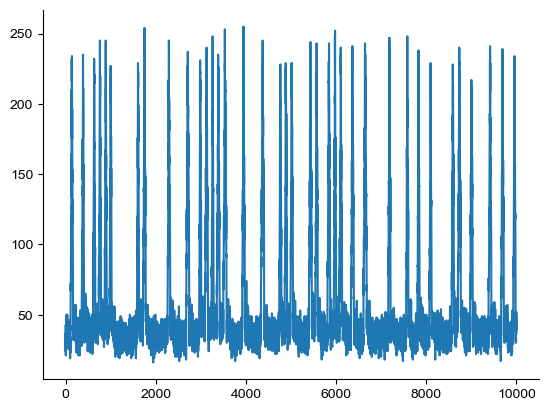

In [18]:
plt.plot(Y[0:10000,6])

In [17]:
# ============================================================
# Type-specific sanity check plots — one figure per neuron group
# ============================================================

import warnings
from collections import defaultdict
from scipy.stats import ttest_ind

SAMPLING_RATE = 15.6

# ──────────────────────────────────────────────────────────────
# Low-level helpers
# ──────────────────────────────────────────────────────────────

def _get_trial_activity(Y_neuron, metadata, trial_idx):
    return Y_neuron[metadata['trial_id'] == trial_idx]


def _safe_mean(arr):
    arr = np.asarray(arr, dtype=float)
    return np.nanmean(arr) if arr.size > 0 else np.nan


def _safe_sem(arr):
    arr = np.asarray(arr, dtype=float)
    arr = arr[np.isfinite(arr)]
    return arr.std() / np.sqrt(len(arr)) if len(arr) > 1 else 0.0


def _bar_panel(ax, groups, title, ylabel='Mean Activity\n(scaled ΔF/F)', fontsize=9):
    """
    Generic bar plot with SEM error bars and pairwise significance
    between the first two groups.
    """
    COLORS = ['#2ecc71', '#9b59b6', '#3498db', '#e74c3c',
              '#f39c12', '#1abc9c', '#e67e22', '#95a5a6']

    labels = list(groups.keys())
    vals   = [np.asarray(groups[k], dtype=float) for k in labels]
    means  = [_safe_mean(v) for v in vals]
    sems   = [_safe_sem(v)  for v in vals]

    # Skip entirely if all means are NaN (e.g. empty outcome group)
    finite_means = [m for m in means if np.isfinite(m)]
    if not finite_means:
        ax.set_title(title + '\n(no data)', fontsize=fontsize)
        return means, sems

    xs = list(range(len(labels)))
    ax.bar(xs, means, yerr=sems,
           color=COLORS[:len(labels)], alpha=0.65, capsize=5)
    ax.set_xticks(xs)
    ax.set_xticklabels(labels, fontsize=8)
    ax.set_ylabel(ylabel, fontsize=8)
    ax.set_title(title, fontsize=fontsize, fontweight='bold')

    # Significance between first two groups
    v0 = vals[0][np.isfinite(vals[0])]
    v1 = vals[1][np.isfinite(vals[1])] if len(vals) >= 2 else np.array([])
    if len(v0) > 1 and len(v1) > 1:
        _, p = ttest_ind(v0, v1)
        sig  = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'n.s.'))
        finite_sems = [s for s in sems if np.isfinite(s)]
        ymax = max(finite_means) + (max(finite_sems) if finite_sems else 0) * 1.5
        ax.text(0.5, ymax, sig, ha='center', fontsize=11, fontweight='bold',
                transform=ax.get_xaxis_transform())

    return means, sems


def _spatial_psth(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                  split_key, split_vals, split_labels, split_colors,
                  n_pos_bins=25, stem_y_max=500.0):
    """Activity vs. y-position, split by a trial-level categorical key."""
    pos_bins    = np.linspace(0, stem_y_max, n_pos_bins + 1)
    bin_centers = (pos_bins[:-1] + pos_bins[1:]) / 2

    for val, label, color in zip(split_vals, split_labels, split_colors):
        activity_all, position_all = [], []

        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            trial_val = td[split_key]
            # Guard against nan comparisons (nan != anything is always True)
            if isinstance(trial_val, float) and np.isnan(trial_val):
                continue
            if trial_val != val:
                continue
            mask  = metadata['trial_id'] == ti
            act   = Y_neuron[mask]
            y_pos = np.asarray(td['movement']['y_position'])
            n_f   = min(len(act), len(y_pos))
            activity_all.extend(act[:n_f])
            position_all.extend(y_pos[:n_f])

        if not activity_all:
            continue

        activity_all = np.array(activity_all, dtype=float)
        position_all = np.array(position_all, dtype=float)

        b_mean, b_sem, b_centers = [], [], []
        for i in range(n_pos_bins):
            m = (position_all >= pos_bins[i]) & (position_all < pos_bins[i + 1])
            if m.sum() > 0:
                b_mean.append(activity_all[m].mean())
                b_sem.append(activity_all[m].std() / np.sqrt(m.sum()))
                b_centers.append(bin_centers[i])

        if not b_mean:
            continue

        b_mean    = np.array(b_mean)
        b_sem     = np.array(b_sem)
        b_centers = np.array(b_centers)

        valid = np.isfinite(b_mean)
        if valid.sum() < 2:
            continue

        ax.plot(b_centers[valid], b_mean[valid], 'o-', color=color,
                alpha=0.8, linewidth=2, markersize=3, label=label)
        ax.fill_between(b_centers[valid],
                        (b_mean - b_sem)[valid],
                        (b_mean + b_sem)[valid],
                        color=color, alpha=0.2)

    ax.set_xlabel('Y Position (stem)', fontsize=8)
    ax.set_ylabel('Mean Activity', fontsize=8)
    ax.legend(fontsize=7)
    ax.set_xlim(0, stem_y_max)


def _event_aligned_psth(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                         event_key, split_key, split_vals, split_labels, split_colors,
                         pre_frames=20, post_frames=40, sampling_rate=SAMPLING_RATE,
                         min_trials=3):
    """Time-locked PSTH aligned to a trial event, split by a trial-level key."""
    time_axis = np.arange(-pre_frames, post_frames) / sampling_rate * 1000  # ms

    for val, label, color in zip(split_vals, split_labels, split_colors):
        snippets = []
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            if td[split_key] != val:
                continue
            ev_frame = td['events'][event_key]
            mask     = metadata['trial_id'] == ti
            act      = Y_neuron[mask]
            start, stop = ev_frame - pre_frames, ev_frame + post_frames
            if start < 0 or stop > len(act):
                continue
            snippets.append(act[start:stop])

        if len(snippets) < min_trials:
            continue

        snippets   = np.array(snippets, dtype=float)
        mean_trace = snippets.mean(axis=0)
        sem_trace  = snippets.std(axis=0) / np.sqrt(len(snippets))

        ax.plot(time_axis, mean_trace, color=color, linewidth=2, label=label)
        ax.fill_between(time_axis,
                        mean_trace - sem_trace,
                        mean_trace + sem_trace,
                        color=color, alpha=0.2)

    ax.axvline(0, color='k', linestyle='--', linewidth=1, alpha=0.6)
    ax.set_xlabel('Time from event (ms)', fontsize=8)
    ax.set_ylabel('Mean Activity', fontsize=8)
    ax.legend(fontsize=7)


def _velocity_tuning(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                     n_bins=20):
    """Activity vs. binned forward (y) velocity."""
    all_vel, all_act = [], []
    for ti in unique_trials:
        td   = synthetic_glm_dict[ti]
        mask = metadata['trial_id'] == ti
        act  = Y_neuron[mask]
        vel  = np.asarray(td['movement']['y_velocity'])
        n_f  = min(len(act), len(vel))
        all_vel.extend(vel[:n_f])
        all_act.extend(act[:n_f])

    all_vel = np.array(all_vel, dtype=float)
    all_act = np.array(all_act, dtype=float)

    fwd      = all_vel > 0
    vel_bins = np.unique(np.percentile(all_vel[fwd], np.linspace(0, 100, n_bins + 1)))

    b_means, b_sems, b_centers = [], [], []
    for i in range(len(vel_bins) - 1):
        m = (all_vel >= vel_bins[i]) & (all_vel < vel_bins[i + 1])
        if m.sum() > 2:
            b_means.append(all_act[m].mean())
            b_sems.append(all_act[m].std() / np.sqrt(m.sum()))
            b_centers.append((vel_bins[i] + vel_bins[i + 1]) / 2)

    if not b_means:
        return

    b_means   = np.array(b_means)
    b_sems    = np.array(b_sems)
    b_centers = np.array(b_centers)

    ax.plot(b_centers, b_means, 'o-', color='#3498db', linewidth=2, markersize=4)
    ax.fill_between(b_centers, b_means - b_sems, b_means + b_sems,
                    color='#3498db', alpha=0.2)
    ax.set_xlabel('Forward Velocity (units/s)', fontsize=8)
    ax.set_ylabel('Mean Activity', fontsize=8)


# ──────────────────────────────────────────────────────────────
# Per-group panel builders
# Each returns a list of 3 callables: [panel_fn(ax), ...]
# ──────────────────────────────────────────────────────────────

def _panels_choice(neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials):
    def p1(ax):
        by_choice = {0: [], 1: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_choice[td['choice']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Left': by_choice[0], 'Right': by_choice[1]},
                   title='Choice Selectivity')

    def p2(ax):
        by_ctx = {0: [], 1: [], 2: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_ctx[td['context']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Ctx0\n(Cong)': by_ctx[0],
                        'Ctx1\n(Audio)': by_ctx[1],
                        'Ctx2\n(Vis)': by_ctx[2]},
                   title='Context Modulation')
        if neuron.context_modulation:
            ax.set_title('Context-Dependent', fontsize=8, color='red', fontweight='bold')
            mod_str = ', '.join([f'C{k}:{v:.1f}x'
                                 for k, v in neuron.context_modulation.items()])
            ax.text(0.5, -0.28, f'Expected: {mod_str}', ha='center', fontsize=7,
                    transform=ax.transAxes, style='italic')
        else:
            ax.set_title('Context-Invariant', fontsize=8, color='green', fontweight='bold')

    def p3(ax):
        _spatial_psth(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                      split_key='choice', split_vals=[0, 1],
                      split_labels=['Left', 'Right'],
                      split_colors=['#2ecc71', '#9b59b6'])
        ax.set_title('Spatial Tuning by Choice', fontsize=8, style='italic')

    return [p1, p2, p3]


def _panels_sound(neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials):
    def p1(ax):
        by_stim = {-90.0: [], 90.0: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            astim = td['Audio_Stim']
            if isinstance(astim, float) and np.isnan(astim):
                continue   # context 1 has no audio stimulus
            if astim in by_stim:
                by_stim[astim].append(
                    _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Left Audio\n(-90°)': by_stim[-90.0],
                        'Right Audio\n(+90°)': by_stim[90.0]},
                   title='Auditory Stimulus Selectivity')

    def p2(ax):
        by_ctx = {0: [], 1: [], 2: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_ctx[td['context']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Ctx0\n(Cong)': by_ctx[0],
                        'Ctx1\n(Audio)': by_ctx[1],
                        'Ctx2\n(Vis)': by_ctx[2]},
                   title='Context Modulation')

    def p3(ax):
        # Only use trials that have an audio stimulus (ctx 0 and ctx 2)
        audio_trials = [ti for ti in unique_trials
                        if not (isinstance(synthetic_glm_dict[ti]['Audio_Stim'], float)
                                and np.isnan(synthetic_glm_dict[ti]['Audio_Stim']))]
        _spatial_psth(ax, Y_neuron, metadata, synthetic_glm_dict, audio_trials,
                      split_key='Audio_Stim', split_vals=[-90.0, 90.0],
                      split_labels=['Left Audio', 'Right Audio'],
                      split_colors=['#e74c3c', '#3498db'])
        ax.set_title('Spatial Tuning by Audio Stim\n(ctx 0 & 2 only)', fontsize=8, style='italic')

    return [p1, p2, p3]


def _panels_visual(neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials):
    def p1(ax):
        by_stim = {0.0: [], 90.0: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            vstim = td['Visual_Stim']
            if isinstance(vstim, float) and np.isnan(vstim):
                continue   # context 2 has no visual stimulus
            if vstim in by_stim:
                by_stim[vstim].append(
                    _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'0° Visual': by_stim[0.0], '90° Visual': by_stim[90.0]},
                   title='Visual Stimulus Selectivity')

    def p2(ax):
        by_ctx = {0: [], 1: [], 2: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_ctx[td['context']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Ctx0\n(Cong)': by_ctx[0],
                        'Ctx1\n(Audio)': by_ctx[1],
                        'Ctx2\n(Vis)': by_ctx[2]},
                   title='Context Modulation')

    def p3(ax):
        # Only use trials that have a visual stimulus (ctx 0 and ctx 1)
        visual_trials = [ti for ti in unique_trials
                         if not (isinstance(synthetic_glm_dict[ti]['Visual_Stim'], float)
                                 and np.isnan(synthetic_glm_dict[ti]['Visual_Stim']))]
        _spatial_psth(ax, Y_neuron, metadata, synthetic_glm_dict, visual_trials,
                      split_key='Visual_Stim', split_vals=[0.0, 90.0],
                      split_labels=['0° Visual', '90° Visual'],
                      split_colors=['#f39c12', '#8e44ad'])
        ax.set_title('Spatial Tuning by Visual Stim\n(ctx 0 & 1 only)', fontsize=8, style='italic')

    return [p1, p2, p3]


def _panels_turn_onset(neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials):
    def p1(ax):
        by_choice = {0: [], 1: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_choice[td['choice']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Left Turn': by_choice[0], 'Right Turn': by_choice[1]},
                   title='Turn Selectivity')

    def p2(ax):
        _event_aligned_psth(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                             event_key='choice_frame',
                             split_key='choice', split_vals=[0, 1],
                             split_labels=['Left Turn', 'Right Turn'],
                             split_colors=['#2ecc71', '#9b59b6'],
                             pre_frames=20, post_frames=40)
        ax.set_title('PSTH Aligned to Turn Onset', fontsize=8, style='italic')

    def p3(ax):
        _spatial_psth(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                      split_key='choice', split_vals=[0, 1],
                      split_labels=['Left Turn', 'Right Turn'],
                      split_colors=['#2ecc71', '#9b59b6'])
        ax.set_title('Spatial Tuning by Turn Direction', fontsize=8, style='italic')

    return [p1, p2, p3]


def _panels_reward(neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials):
    """Panels for outcome-selective neurons (hit, miss, or value)."""
    def p1(ax):
        by_outcome = {1: [], 0: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_outcome[td['outcome']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Correct\n(hit)': by_outcome[1], 'Error\n(miss)': by_outcome[0]},
                   title='Outcome Selectivity')

    def p2(ax):
        # Separate PSTHs for correct and error trials, aligned to reward/iti event
        correct_trials = [ti for ti in unique_trials
                          if synthetic_glm_dict[ti]['outcome'] == 1]
        error_trials   = [ti for ti in unique_trials
                          if synthetic_glm_dict[ti]['outcome'] == 0]

        for trials, label, color in [
            (correct_trials, 'Correct → reward', '#27ae60'),
            (error_trials,   'Error  → ITI',     '#e74c3c'),
        ]:
            snippets = []
            for ti in trials:
                td       = synthetic_glm_dict[ti]
                ref      = td['events']['reward_frame']  # reward or iti_start
                mask     = metadata['trial_id'] == ti
                act      = Y_neuron[mask]
                pre, post = 15, 50
                start, stop = ref - pre, ref + post
                if start < 0 or stop > len(act):
                    continue
                snippets.append(act[start:stop])
            if len(snippets) >= 3:
                snip = np.array(snippets, dtype=float)
                t    = np.arange(-15, 50) / SAMPLING_RATE * 1000
                m    = snip.mean(0)
                s    = snip.std(0) / np.sqrt(len(snip))
                ax.plot(t, m, color=color, linewidth=2, label=label)
                ax.fill_between(t, m - s, m + s, color=color, alpha=0.2)

        ax.axvline(0, color='k', linestyle='--', linewidth=1, alpha=0.6)
        ax.set_xlabel('Time from outcome (ms)', fontsize=8)
        ax.set_ylabel('Mean Activity', fontsize=8)
        ax.legend(fontsize=7)
        ax.set_title('PSTH Aligned to Outcome', fontsize=8, style='italic')

    def p3(ax):
        by_ctx = {0: [], 1: [], 2: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_ctx[td['context']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Ctx0\n(Cong)': by_ctx[0],
                        'Ctx1\n(Visual)': by_ctx[1],
                        'Ctx2\n(Audio)': by_ctx[2]},
                   title='Context Modulation (ref)')

    return [p1, p2, p3]


def _panels_velocity(neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials):
    def p1(ax):
        _velocity_tuning(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials)
        ax.set_title('Velocity Tuning', fontsize=8, style='italic')

    def p2(ax):
        by_choice = {0: [], 1: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_choice[td['choice']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Left': by_choice[0], 'Right': by_choice[1]},
                   title='Choice Selectivity (should be n.s.)')

    def p3(ax):
        _spatial_psth(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                      split_key='choice', split_vals=[0, 1],
                      split_labels=['Left', 'Right'],
                      split_colors=['#2ecc71', '#9b59b6'])
        ax.set_title('Spatial Tuning', fontsize=8, style='italic')

    return [p1, p2, p3]


def _panels_position(neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials):
    def p1(ax):
        _spatial_psth(ax, Y_neuron, metadata, synthetic_glm_dict, unique_trials,
                      split_key='choice', split_vals=[0, 1],
                      split_labels=['Left', 'Right'],
                      split_colors=['#2ecc71', '#9b59b6'])
        ax.set_title('Spatial Tuning (choice-invariant expected)', fontsize=8, style='italic')

    def p2(ax):
        by_choice = {0: [], 1: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_choice[td['choice']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Left': by_choice[0], 'Right': by_choice[1]},
                   title='Choice Selectivity (should be n.s.)')

    def p3(ax):
        by_ctx = {0: [], 1: [], 2: []}
        for ti in unique_trials:
            td = synthetic_glm_dict[ti]
            by_ctx[td['context']].append(
                _get_trial_activity(Y_neuron, metadata, ti).mean())
        _bar_panel(ax, {'Ctx0': by_ctx[0], 'Ctx1': by_ctx[1], 'Ctx2': by_ctx[2]},
                   title='Context Modulation (should be n.s.)')

    return [p1, p2, p3]


# ──────────────────────────────────────────────────────────────
# Dispatch table
# ──────────────────────────────────────────────────────────────

GROUP_PANEL_BUILDERS = {
    'choice_spatial': _panels_choice,
    'sound':          _panels_sound,
    'visual':         _panels_visual,
    'turn_onset':     _panels_turn_onset,
    'reward_hit':     _panels_reward,
    'reward_miss':    _panels_reward,
    'velocity':       _panels_velocity,
    'position_only':  _panels_position,
}

GROUP_TITLES = {
    'choice_spatial': 'Choice Neurons',
    'sound':          'Auditory Stimulus Neurons',
    'visual':         'Visual Stimulus Neurons',
    'turn_onset':     'Turn Onset Neurons',
    'reward_hit':     'Reward Neurons — Correct Trials (Hit)',
    'reward_miss':    'Reward Neurons — Error Trials (Miss)',
    'velocity':       'Velocity Neurons',
    'position_only':  'Position Neurons',
    'mixed':          'Mixed Selectivity Neurons',
}

COLUMN_HEADERS = {
    'choice_spatial': ['Choice Selectivity',   'Context Modulation',    'Spatial Tuning by Choice'],
    'sound':          ['Auditory Selectivity',  'Context Modulation',    'Spatial Tuning by Audio'],
    'visual':         ['Visual Selectivity',    'Context Modulation',    'Spatial Tuning by Visual'],
    'turn_onset':     ['Turn Selectivity',      'PSTH @ Turn Onset',     'Spatial Tuning by Turn'],
    'reward_hit':     ['Outcome Selectivity',   'PSTH @ Outcome Event',  'Context Ref.'],
    'reward_miss':    ['Outcome Selectivity',   'PSTH @ Outcome Event',  'Context Ref.'],
    'velocity':       ['Velocity Tuning',       'Choice Ref.',           'Spatial Tuning'],
    'position_only':  ['Spatial Tuning',        'Choice Ref.',           'Context Ref.'],
    'mixed':          ['Panel A',               'Panel B',               'Panel C'],
}


# ──────────────────────────────────────────────────────────────
# Main: one figure per neuron group
# ──────────────────────────────────────────────────────────────

def plot_neurons_by_group(synthetic_glm_dict, Y, metadata, ground_truth,
                          neuron_library, sampling_rate=SAMPLING_RATE):
    """
    Produce one figure per neuron group, each with one row per neuron
    and three type-specific panels per row.

    Mixed neurons (>1 group) are collected into a separate 'mixed' figure
    where each group's 3 panels occupy a separate row.

    Returns
    -------
    figures : dict  {group_name: matplotlib.figure.Figure}
    """
    unique_trials = np.unique(metadata['trial_id'])

    # ── Partition neurons into groups ────────────────────────
    group_to_neurons = defaultdict(list)   # group_name → [(ni, neuron), ...]

    for ni, neuron in enumerate(neuron_library):
        # Collect groups from global weight_params AND per_context_weight_params
        all_groups_raw = list(neuron.weight_params.keys())
        if neuron.per_context_weight_params:
            for ctx_wp in neuron.per_context_weight_params.values():
                all_groups_raw += list(ctx_wp.keys())
        known_groups = list(dict.fromkeys(   # unique, order-preserving
            g for g in all_groups_raw if g in GROUP_PANEL_BUILDERS
        ))

        if len(known_groups) > 1:
            group_to_neurons['mixed'].append((ni, neuron))
        elif len(known_groups) == 1:
            group_to_neurons[known_groups[0]].append((ni, neuron))
        # neurons with no known group are silently skipped

    figures = {}

    for group_name, neuron_list in group_to_neurons.items():

        if group_name == 'mixed':
            # Each mixed neuron gets one row per constituent group
            row_specs = []   # (ni, neuron, group_key) one entry per panel-row
            for ni, neuron in neuron_list:
                all_g = list(neuron.weight_params.keys())
                if neuron.per_context_weight_params:
                    for ctx_wp in neuron.per_context_weight_params.values():
                        all_g += [g for g in ctx_wp if g not in all_g]
                for g in all_g:
                    if g in GROUP_PANEL_BUILDERS:
                        row_specs.append((ni, neuron, g))
        else:
            row_specs = [(ni, neuron, group_name) for ni, neuron in neuron_list]

        n_rows = len(row_specs)
        if n_rows == 0:
            continue

        fig, axes = plt.subplots(n_rows, 3, figsize=(18, 3.2 * n_rows),
                                 squeeze=False)

        col_headers = COLUMN_HEADERS.get(group_name, ['Panel A', 'Panel B', 'Panel C'])

        for row_idx, (ni, neuron, g_key) in enumerate(row_specs):
            Y_neuron  = Y[:, ni]
            panel_fns = GROUP_PANEL_BUILDERS[g_key](
                neuron, Y_neuron, metadata, synthetic_glm_dict, unique_trials)

            for col_idx, panel_fn in enumerate(panel_fns):
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore', RuntimeWarning)
                    panel_fn(axes[row_idx, col_idx])

            # Row label: neuron name (+ group tag for mixed figures)
            row_label = neuron.name
            if group_name == 'mixed':
                row_label += f'\n[{g_key}]'
            current_title = axes[row_idx, 0].get_title()
            axes[row_idx, 0].set_title(
                f'{row_label}\n{current_title}', fontsize=8, fontweight='bold')

        # Column headers on first row only
        for col_idx, header in enumerate(col_headers):
            axes[0, col_idx].text(0.5, 1.20, header,
                                  ha='center', fontsize=11, fontweight='bold',
                                  transform=axes[0, col_idx].transAxes)

        fig.suptitle(GROUP_TITLES.get(group_name, group_name),
                     fontsize=14, fontweight='bold', y=1.01)
        plt.tight_layout()
        plt.subplots_adjust(hspace=0.6)

        figures[group_name] = fig

    return figures


# # ── Run ───────────────────────────────────────────────────────
# print("\nGenerating per-group neuron tuning figures...")
# print("=" * 70)

# figures = plot_neurons_by_group(
#     synthetic_glm_dict=synthetic_glm_dict,
#     Y=Y,
#     metadata=metadata,
#     ground_truth=ground_truth,
#     neuron_library=neuron_library,
#     sampling_rate=15.6,
# )

# print(f"\n✓ Generated {len(figures)} figures:")
# for name in figures:
#     print(f"   • {GROUP_TITLES.get(name, name)}")

# print("\nSanity Check Guide:")
# print("-" * 70)
# print("• choice_spatial  → L/R bar should differ; context bar flat (invariant) or graded (dependent)")
# print("• sound/visual    → stimulus bar should differ; spatial PSTH tracks stimulus side")
# print("• turn_onset      → event-aligned PSTH shows peri-turn transient; bar shows L/R selectivity")
# print("• reward          → event-aligned PSTH shows post-reward transient; choice bar should be n.s.")
# print("• velocity        → monotonic increase with forward speed; choice/spatial should be n.s.")
# print("• position_only   → spatial PSTH peaks at place field; choice/context bars should be n.s.")
# print("• mixed           → each constituent group gets its own row of type-specific panels")

## Save simulated neurons

In [13]:
save_dir = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_data/'

# Create directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Derive group_indices from predictor_info
group_indices = {name: list(range(info['start'], info['end'])) 
                 for name, info in predictor_info.items()}

# Prepare data dictionary with all relevant information
glm_data = {
    # Core data matrices
    'X': X,
    'Y': Y,
    
    # Metadata (frame-level trial information)
    'metadata': metadata,
    
    # Predictor information
    'predictor_names': predictor_names,
    'predictor_info': predictor_info,
    'group_indices': group_indices,
    
    # Per-trial data (equivalent of design_matrices for simulated data)
    'synthetic_glm_dict': synthetic_glm_dict,
    
    # Ground truth weights (unique to simulated data)
    'ground_truth': ground_truth,
    
    # Builder configuration (for reproducibility)
    'builder_params': {
        'sampling_rate': 15.6,
        'n_pos_bases': 10,
        'stem_y_max': 500.0,
        'pos_bump_width_ratio': 4.0,
        'audio_start_position': 50.0,
        'n_vel_bases': 5,
        'n_place_fields': 30,
        'n_turn_bases': 4,
        'turn_window': 1.0,
        'n_reward_bases': 8,
        'reward_window': 2.0,
        'temporal_bump_width_ratio': 4.0,
    },
    
    # Additional info
    'neural_metric': 'deconv',
    'mouse_ID': 'simulated',
    'date': 'simulated',
}

# Save to pickle file
save_path = os.path.join(save_dir, 'simulated_glm_data.pkl')

print(f"Saving GLM data to: {save_path}")
print(f"Data shapes:")
print(f"  X: {X.shape}")
print(f"  Y: {Y.shape}")
print(f"  Metadata: {len(metadata)} variables, {len(metadata['trial_id'])} frames")
print(f"  Predictors: {len(predictor_names)}")
print(f"  Trials: {len(synthetic_glm_dict)}")
print(f"  Ground truth neurons: {ground_truth['w_true'].shape[1]}")

with open(save_path, 'wb') as f:
    pickle.dump(glm_data, f, protocol=pickle.HIGHEST_PROTOCOL)

# Check file size
file_size_mb = os.path.getsize(save_path) / (1024**2)
print(f"\n✓ Saved successfully!")
print(f"  File size: {file_size_mb:.2f} MB")
print(f"  Location: {save_path}")

Saving GLM data to: /Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_data/simulated_glm_data.pkl
Data shapes:
  X: (40224, 146)
  Y: (40224, 22)
  Metadata: 8 variables, 40224 frames
  Predictors: 146
  Trials: 300
  Ground truth neurons: 22

✓ Saved successfully!
  File size: 62.10 MB
  Location: /Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model/simulated_data/simulated_glm_data.pkl
